# Solution: Mission 01 — Campaign Targeting Pipeline

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

RNG = 42

from sklearn.model_selection import train_test_split

bank = datasets.bank_marketing()
y = (bank.pop("y") == "yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(bank, y, test_size=0.25, stratify=y, random_state=RNG)   # keep X_test untouched
CALL_COST, GAIN = 5, 50                       # EUR per call, EUR profit per subscription
print(X_train.shape, X_test.shape, f"positive rate {y.mean():.3f}")

(30891, 20) (10297, 20) positive rate 0.113


## Task 1: Leakage Review

| Column | Known before the call? | Decision |
| :--- | :--- | :--- |
| age, job, marital, education, default, housing, loan | yes (client data) | keep |
| contact (cellular/telephone) | yes (the number we will call) | keep |
| month, day_of_week | yes (the planned call date) | keep |
| **duration** | **no**: length of this call | **remove** |
| campaign | the number of contacts in this campaign *including* this one; known for the planned call | keep |
| pdays, previous, poutcome | yes (history of earlier campaigns) | keep |
| emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed | yes (published economic indicators) | keep |

In [2]:
X_train = X_train.drop(columns="duration")
X_test = X_test.drop(columns="duration")
cat = X_train.select_dtypes(include="str").columns.tolist()
num = X_train.columns.difference(cat).tolist()
print(f"{len(num)} numeric and {len(cat)} categorical inputs")

9 numeric and 10 categorical inputs


## Task 2: Schema

In [3]:
import pandera.pandas as pa

schema = pa.DataFrameSchema(
    {**{c: pa.Column(str, pa.Check.isin(sorted(X_train[c].unique()))) for c in cat},
     "age": pa.Column(int, pa.Check.in_range(17, 100)),
     "campaign": pa.Column(int, pa.Check.ge(1)),
     "pdays": pa.Column(int, pa.Check.ge(0)),               # 999 = never contacted before
     "previous": pa.Column(int, pa.Check.ge(0)),
     **{c: pa.Column(float) for c in ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]}},
    strict=True)
schema.validate(X_train)
print("X_train passes the schema; columns:", len(schema.columns))
print("pdays == 999 (never contacted):", f"{(X_train['pdays'] == 999).mean():.1%}")

X_train passes the schema; columns: 19
pdays == 999 (never contacted): 96.2%


`pdays = 999` means "never contacted before": a disguised missing value. The pipeline adds an explicit flag for it.

## Task 3: Pipeline and Model Comparison

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

def add_flags(X):
    X = X.copy()
    X["never_contacted"] = (X["pdays"] == 999).astype(int)
    X["pdays"] = X["pdays"].where(X["pdays"] != 999, -1)
    return X

def make(model):
    pre = ColumnTransformer([("num", StandardScaler(), num + ["never_contacted"]),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return make_pipeline(FunctionTransformer(add_flags), pre, model)

cv = StratifiedKFold(5, shuffle=True, random_state=RNG)
candidates = {"logistic regression": LogisticRegression(max_iter=3000, C=0.5),
              "gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=RNG)}
scores = {k: cross_val_score(make(m), X_train, y_train, cv=cv, scoring="average_precision") for k, m in candidates.items()}
for k, v in scores.items():
    print(f"{k:<20} PR AUC {v.mean():.4f} ± {v.std():.4f}")
best_name = max(scores, key=lambda k: scores[k].mean())
print("chosen:", best_name)

logistic regression  PR AUC 0.4446 ± 0.0214
gradient boosting    PR AUC 0.4646 ± 0.0136
chosen: gradient boosting


## Task 4: Profit-Maximising Threshold (Training Data Only)

tuned threshold: 0.100 (break-even probability = cost/gain = 0.10)


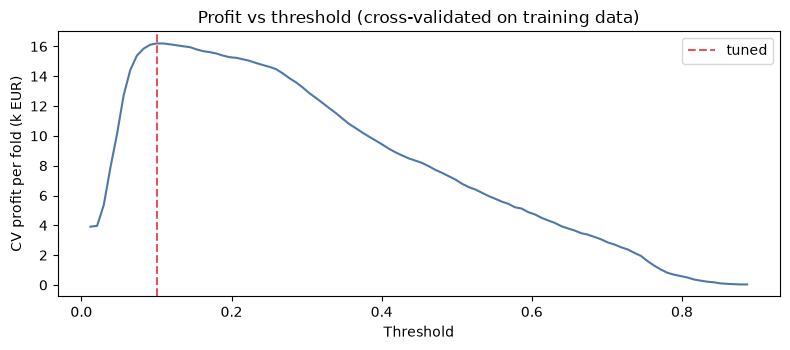

In [5]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import TunedThresholdClassifierCV

def profit(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return GAIN * int(((y_pred == 1) & (y_true == 1)).sum()) - CALL_COST * int((y_pred == 1).sum())

tuned = TunedThresholdClassifierCV(make(candidates[best_name]), scoring=make_scorer(profit), cv=cv, random_state=RNG,
                                   store_cv_results=True).fit(X_train, y_train)
print(f"tuned threshold: {tuned.best_threshold_:.3f} (break-even probability = cost/gain = {CALL_COST / GAIN:.2f})")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(tuned.cv_results_["thresholds"], tuned.cv_results_["scores"] / 1000, color="#4E79A7")
ax.axvline(tuned.best_threshold_, color="#E15759", ls="--", label="tuned")
ax.set(xlabel="Threshold", ylabel="CV profit per fold (k EUR)", title="Profit vs threshold (cross-validated on training data)")
ax.legend()
plt.tight_layout()
plt.show()

The tuned threshold is close to the break-even probability of 0.10: calling a client is worth it when the chance of success is above 5 € / 50 €, if the model's probabilities are well calibrated.

## Task 5: Final Evaluation on the Untouched Test Set

In [6]:
from sklearn.metrics import average_precision_score

final = tuned.estimator_
p = final.predict_proba(X_test)[:, 1]
rows = []
for name, pred in [("call everybody", np.ones(len(y_test), dtype=int)), ("model, threshold 0.5", (p >= 0.5).astype(int)),
                   (f"model, tuned threshold {tuned.best_threshold_:.2f}", tuned.predict(X_test))]:
    rows.append({"strategy": name, "calls": int(pred.sum()), "subscriptions": int((pred & y_test.to_numpy()).sum()),
                 "profit_EUR": profit(y_test, pred)})
result = pd.DataFrame(rows).set_index("strategy")
print(f"test PR AUC: {average_precision_score(y_test, p):.3f} (random: {y_test.mean():.3f})")
result

test PR AUC: 0.495 (random: 0.113)


,calls,subscriptions,profit_EUR
strategy,,,
call everybody,10297,1160,6515
"model, threshold 0.5",427,293,12515
"model, tuned threshold 0.10",2222,783,28040


## Task 6: Recommendation

In [7]:
best = result["profit_EUR"].idxmax()
everybody = result.loc["call everybody"]
chosen = result.iloc[-1]
print(f"1. Use the model with the tuned threshold: on unseen clients it earned {chosen.profit_EUR:,} EUR, "
      f"compared with {everybody.profit_EUR:,} EUR when calling everybody.")
print(f"2. It needs {chosen.calls:,} calls instead of {everybody.calls:,} ({chosen.calls / everybody.calls:.0%}), "
      f"and still finds {chosen.subscriptions / everybody.subscriptions:.0%} of the subscribers.")
print("3. The model uses only information known before the call; call duration was removed on purpose.")
print("4. The threshold follows the cost of a call and the value of a subscription: if these change, re-tune it.")
print("5. Economic conditions change over time (Lesson 09): monitor the hit rate monthly and retrain when it drops.")

1. Use the model with the tuned threshold: on unseen clients it earned 28,040 EUR, compared with 6,515 EUR when calling everybody.
2. It needs 2,222 calls instead of 10,297 (22%), and still finds 68% of the subscribers.
3. The model uses only information known before the call; call duration was removed on purpose.
4. The threshold follows the cost of a call and the value of a subscription: if these change, re-tune it.
5. Economic conditions change over time (Lesson 09): monitor the hit rate monthly and retrain when it drops.
